In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.stats import spearmanr

In [ ]:
df = pd.read_csv("../data/metabeeai/llm_simulation_results_19_llm_pairs.csv")

# import RAG
evals = pd.read_csv("../data/metabeeai/faithfulness_precision_recall_gpt_4o.csv")
geval = pd.read_csv("../data/metabeeai/geval_completeness_accuracy_gpt_4.1.csv")


In [ ]:
# Primate Welfare Data, re-run this dataframe and proceed as usual. 
df = pd.read_csv("../data/llm_simulation_results_primate_welfare.csv")
evals = pd.read_csv("../data/faithfulness_precision_recall_gpt_4o_primate_welfare.csv")
geval = pd.read_csv("../data/geval_completeness_accuracy_gpt_4.1_primate_welfare.csv")

In [143]:
deepeval_cols = [
    "index_model_pair", "question", "paper_id",
    "faithfulness_score",
    "faithfulness_evaluation_cost",
    "contextual_precision_score",
    "contextual_precision_evaluation_cost",
    "contextual_recall_score",
    "contextual_recall_evaluation_cost"
]

geval_cols = [
    "index_model_pair", "question", "paper_id",
    "completeness_score",
    "completeness_evaluation_cost",
    "accuracy_score",
    "accuracy_evaluation_cost"
]

deepeval_small = evals[deepeval_cols].copy()
geval_small = geval[geval_cols].copy()


In [ ]:

# create pair name for further plotting
df["pair_name"] = (
    df["relevance_model"].str.split("/").str[-1]
    +
    " + " +
    df["answer_model"].str.split("/").str[-1]
)

merged = df.merge(
    deepeval_small,
    on=["index_model_pair", "question", "paper_id"],
    how="left"
)

merged = merged.merge(
    geval_small,
    on=["index_model_pair", "question", "paper_id"],
    how="left"
)

# check if the df contain NaN
print(merged.shape)
print(merged.isna().mean().sort_values(ascending=False).head(10))

(1701, 24)
answer                         0.001176
index_model_pair               0.000000
paper_id                       0.000000
question                       0.000000
answer_rev3                    0.000000
reason                         0.000000
chunk_ids                      0.000000
relevance_prompt_tokens        0.000000
relevance_completion_tokens    0.000000
answer_prompt_tokens           0.000000
dtype: float64


In [145]:
df

,index_model_pair,question,paper_id,answer_rev3,answer,reason,chunk_ids,relevance_prompt_tokens,relevance_completion_tokens,answer_prompt_tokens,answer_completion_tokens,relevance_model,answer_model,pair_name
0,0,design,1,Overview: Examines the influence of foraging e...,1. Overview: Examines the influence of foragin...,The studies collectively examine the effects o...,"['eb8126f0-9400-4c21-ba97-a19200233960', '50c8...",13579,11,8100,939,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini,gpt-4o-mini + gpt-4o-mini
1,0,population,1,Species 1: Rhesus macaques; sex: M and F; age ...,Species 1: Rhesus macaques; sex: M and F; age ...,The provided text contains specific details ab...,['1907db71-b59c-4224-975e-0ab114ed784b'],14216,16,8086,470,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini,gpt-4o-mini + gpt-4o-mini
2,0,welfare,1,1. Measure: Behavior assessments; Measure desc...,1. Measure: Behavioral assessments; Measure de...,The study utilized various measures to assess ...,"['1907db71-b59c-4224-975e-0ab114ed784b', '7d96...",83,20,5095,1284,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini,gpt-4o-mini + gpt-4o-mini
3,0,design,2,1. Overview: Evaluates the behavioral impact o...,1. Overview: Examines the effects of choice in...,The studies collectively investigate the impac...,"['8b5e5b15-f79f-4eb5-bb90-a0f60189e3f1', '4450...",8411,16,7093,839,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini,gpt-4o-mini + gpt-4o-mini
4,0,population,2,Species 1: Western lowland gorillas; sex: M an...,Species 1: Western lowland gorillas; sex: M an...,The text provides specific details about the s...,"['f8737585-e4a8-49d1-8130-631870fa6fd0', '6f59...",9048,16,11485,934,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini,gpt-4o-mini + gpt-4o-mini
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1696,8,population,64,Species 1: Cebus (Capuchin monkeys); sex: M an...,Species 1: Common squirrel monkey; sex: M and ...,The information was synthesized from multiple ...,"['b4234224-cdc9-42e2-b450-a538d0c708b3', '0334...",17472,23,11406,796,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,gemini-3.1-flash-lite-preview + gemini-3.1-fla...
1697,8,welfare,64,1. Measure: Interspecific and intraspecific in...,1. Measure: Activity budget and spatial use; M...,The study used scan sampling for activity budg...,"['0662160b-aa96-4f7d-81ee-42a6603e9a99', 'da08...",17793,39,24529,2093,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,gemini-3.1-flash-lite-preview + gemini-3.1-fla...
1698,8,design,65,1. Overview: Examines the effect of zoo enviro...,1. Overview: Examines the impact of zoo enviro...,The provided text chunks describe multiple stu...,"['67692331-a9d6-4e6c-b987-58665ab73e83', '04a8...",12641,20,6516,715,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,gemini-3.1-flash-lite-preview + gemini-3.1-fla...
1699,8,population,65,Species 1: Ring-tailed lemurs; sex: M and F; a...,Species 1: Ring-tailed lemurs; sex: M and F; a...,The study focuses on a single group of free-ra...,"['fa5961c8-3dbd-4608-93e1-fa951ac104dc', '4b3a...",13294,20,10617,559,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,gemini-3.1-flash-lite-preview + gemini-3.1-fla...


In [146]:
pricing = pd.read_csv("../data/token_price_per_million.csv")

In [147]:
price_idx = pricing.set_index("model").to_dict("index")
def calculate_cost(row):

    rel_model = row["relevance_model"]
    ans_model = row["answer_model"]

    rel_input_price = price_idx[rel_model]["input_price_per_million"]
    rel_output_price = price_idx[rel_model]["output_price_per_million"]

    ans_input_price = price_idx[ans_model]["input_price_per_million"]
    ans_output_price = price_idx[ans_model]["output_price_per_million"]

    relevance_cost = (
        row["relevance_prompt_tokens"] / 1_000_000 * rel_input_price
        +
        row["relevance_completion_tokens"] / 1_000_000 * rel_output_price
    )

    answer_cost = (
        row["answer_prompt_tokens"] / 1_000_000 * ans_input_price
        +
        row["answer_completion_tokens"] / 1_000_000 * ans_output_price
    )

    return relevance_cost + answer_cost

merged["total_cost_usd"] = df.apply(calculate_cost, axis=1)

In [141]:
merged

,index_model_pair,question,paper_id,answer_rev3,answer,reason,chunk_ids,relevance_prompt_tokens,relevance_completion_tokens,answer_prompt_tokens,...,contextual_recall_score,contextual_recall_evaluation_cost,completeness_score,completeness_evaluation_cost,accuracy_score,accuracy_evaluation_cost,total_cost_usd,evaluation_cost,pipeline_cost,combined_quality
0,0,bee_species,216,1. Apis mellifera,1. Apis mellifera; 2. Myzus persicae,The study specifically tested the species ment...,"['0a220901-0aae-4608-b421-a6d046d5f959', '83f3...",14849,9,6613,...,1.0,0.005010,0.589609,0.002010,0.500000,0.001926,0.003372,0.027273,0.030645,0.817922
1,0,pesticides,216,"1. Compound 7b: 5 and 10 mg/L, contact exposur...","1. Compound 7b: 5 × 10⁴ mg/L, contact exposure...",The text specifies the compounds tested and th...,['ae976fce-7915-4aa6-92f8-304ce5494adf'],14909,13,6636,...,1.0,0.008087,0.402770,0.003022,0.291935,0.002960,0.003533,0.029819,0.033352,0.678941
2,0,additional_stressors,216,No additional stressors were tested.,No additional stressors were tested.,The study did not test any additional stressor...,"['ae976fce-7915-4aa6-92f8-304ce5494adf', '4c51...",15440,9,13870,...,1.0,0.005640,1.000000,0.001744,1.000000,0.001596,0.004605,0.031127,0.035733,0.850000
3,0,bee_species,732,1. Apis mellifera,1. Apis mellifera,The study specifically mentions honey bees in ...,"['e3ec9b5a-ba1f-4f14-a281-7e7ffe7b2ae2', '95df...",13162,9,6414,...,1.0,0.004182,1.000000,0.001762,1.000000,0.001596,0.003092,0.021203,0.024295,1.000000
4,0,pesticides,732,"1. Imidacloprid: 20 μg/kg, oral exposure, 14 days","1. Imidacloprid: 20 ppb, oral exposure, 14 day...",NaN,"['e3ec9b5a-ba1f-4f14-a281-7e7ffe7b2ae2', '95df...",13222,9,7038,...,1.0,0.006143,0.322816,0.002216,0.319683,0.002180,0.003293,0.032346,0.035639,0.599333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,360,additional_stressors,70,No additional stressors were tested.,No additional stressors were tested,Answer generated from available information,"['28e5b49e-7ba6-4b03-a1e6-fa4a7c62bf69', 'b7e0...",0,0,0,...,0.0,0.004055,1.000000,0.001726,1.000000,0.001714,0.000000,0.023015,0.023015,0.700000
1334,360,pesticides,70,"1. Thiacloprid: 2.69 ug/mL, 6.72 ug/mL, and 26...",No pesticides were tested in this study,Answer generated from available information,"['28e5b49e-7ba6-4b03-a1e6-fa4a7c62bf69', 'b7e0...",0,0,0,...,0.0,0.004745,0.000000,0.001956,0.000000,0.001976,0.000000,0.024484,0.024484,0.050000
1335,360,bee_species,52,1. Apis cerana cerana,Species not specified,Answer generated from available information,"['012b0aa0-da7c-4d13-9e5c-009133293770', 'a7d4...",0,0,0,...,1.0,0.003993,0.176629,0.001866,0.098380,0.001862,0.000000,0.022805,0.022805,0.242502
1336,360,pesticides,52,"1. Thiacloprid: 0 mg/L, 130 mg/L, 170 mg/L, 22...",No pesticides were tested in this study,Answer generated from available information,"['012b0aa0-da7c-4d13-9e5c-009133293770', 'a7d4...",0,0,0,...,0.5,0.004962,0.000000,0.001988,0.000000,0.002056,0.000000,0.025456,0.025456,0.075000


In [151]:
# create a combined quality and cost 
merged["evaluation_cost"] = (
    merged["faithfulness_evaluation_cost"] +
    merged["contextual_precision_evaluation_cost"] +
    merged["contextual_recall_evaluation_cost"] +
    merged["completeness_evaluation_cost"] +
    merged["accuracy_evaluation_cost"]
)

merged["pipeline_cost"] = (
    merged["total_cost_usd"] +
    merged["evaluation_cost"]
)

# self-tumning scale 
merged["combined_quality"] = (
    0.30 * merged["faithfulness_score"] +
    0.15 * merged["contextual_precision_score"] +
    0.15 * merged["contextual_recall_score"] +
    0.20 * merged["completeness_score"] +
    0.20 * merged["accuracy_score"]
)

In [152]:
# build a summary table 
summary_geval = merged.groupby(
    ["index_model_pair", "pair_name", "answer_model"]
).agg(
    avg_pipeline_cost=("pipeline_cost", "mean"),
    avg_generation_cost=("total_cost_usd", "mean"),
    avg_evaluation_cost=("evaluation_cost", "mean"),

    avg_faithfulness=("faithfulness_score", "mean"),
    avg_precision=("contextual_precision_score", "mean"),
    avg_recall=("contextual_recall_score", "mean"),
    avg_completeness=("completeness_score", "mean"),
    avg_accuracy=("accuracy_score", "mean"),
    avg_quality=("combined_quality", "mean"),

    n_questions=("question", "count")
).reset_index()

summary_geval["efficiency"] = (
    summary_geval["avg_quality"] /
    summary_geval["avg_pipeline_cost"]
)

summary_geval.sort_values("efficiency", ascending=False).head(10)

,index_model_pair,pair_name,answer_model,avg_pipeline_cost,avg_generation_cost,avg_evaluation_cost,avg_faithfulness,avg_precision,avg_recall,avg_completeness,avg_accuracy,avg_quality,n_questions,efficiency
0,0,gpt-4o-mini + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.037066,0.003317,0.033749,0.929263,0.927754,0.860990,0.568337,0.493930,0.759544,189,20.491780
6,6,gemini-3.1-flash-lite-preview + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.039751,0.004886,0.034865,0.906708,0.944020,0.877641,0.589194,0.523009,0.767702,189,19.312664
2,2,gpt-4o-mini + gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,0.040981,0.005978,0.035004,0.920234,0.949729,0.887341,0.607908,0.581423,0.789497,189,19.264770
1,1,gpt-4o-mini + mistral-large-2512,openrouter/mistralai/mistral-large-2512,0.043019,0.007606,0.035413,0.934962,0.945398,0.882175,0.652345,0.606462,0.806386,189,18.744972
3,3,mistral-large-2512 + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.041836,0.007594,0.034242,0.900243,0.943528,0.880997,0.598078,0.532196,0.769806,189,18.400719
8,8,gemini-3.1-flash-lite-preview + gemini-3.1-fla...,openrouter/google/gemini-3.1-flash-lite-preview,0.045179,0.007663,0.037516,0.900109,0.931252,0.915686,0.639834,0.611329,0.797306,189,17.647645
7,7,gemini-3.1-flash-lite-preview + mistral-large-...,openrouter/mistralai/mistral-large-2512,0.046469,0.008945,0.037524,0.905868,0.928871,0.899364,0.683645,0.636407,0.810006,189,17.431150
5,5,mistral-large-2512 + gemini-3.1-flash-lite-pre...,openrouter/google/gemini-3.1-flash-lite-preview,0.047379,0.010369,0.037010,0.928339,0.948890,0.910143,0.635465,0.601087,0.804667,189,16.983627
4,4,mistral-large-2512 + mistral-large-2512,openrouter/mistralai/mistral-large-2512,0.049123,0.011818,0.037305,0.918640,0.947393,0.898322,0.673573,0.626120,0.812388,189,16.537938


In [153]:
summary_geval["models"] = (
    summary_geval["answer_model"].str.split("/").str[-1]

)

In [154]:
summary_geval["models"].unique()

array(['gpt-4o-mini', 'mistral-large-2512',
       'gemini-3.1-flash-lite-preview'], dtype=object)

In [ ]:
merged.to_csv("19_llm_metabee_cost_performance.csv")
# for primate welfare, uncomment below line
merged.to_csv("primate_welfare_performace_cost.csv")

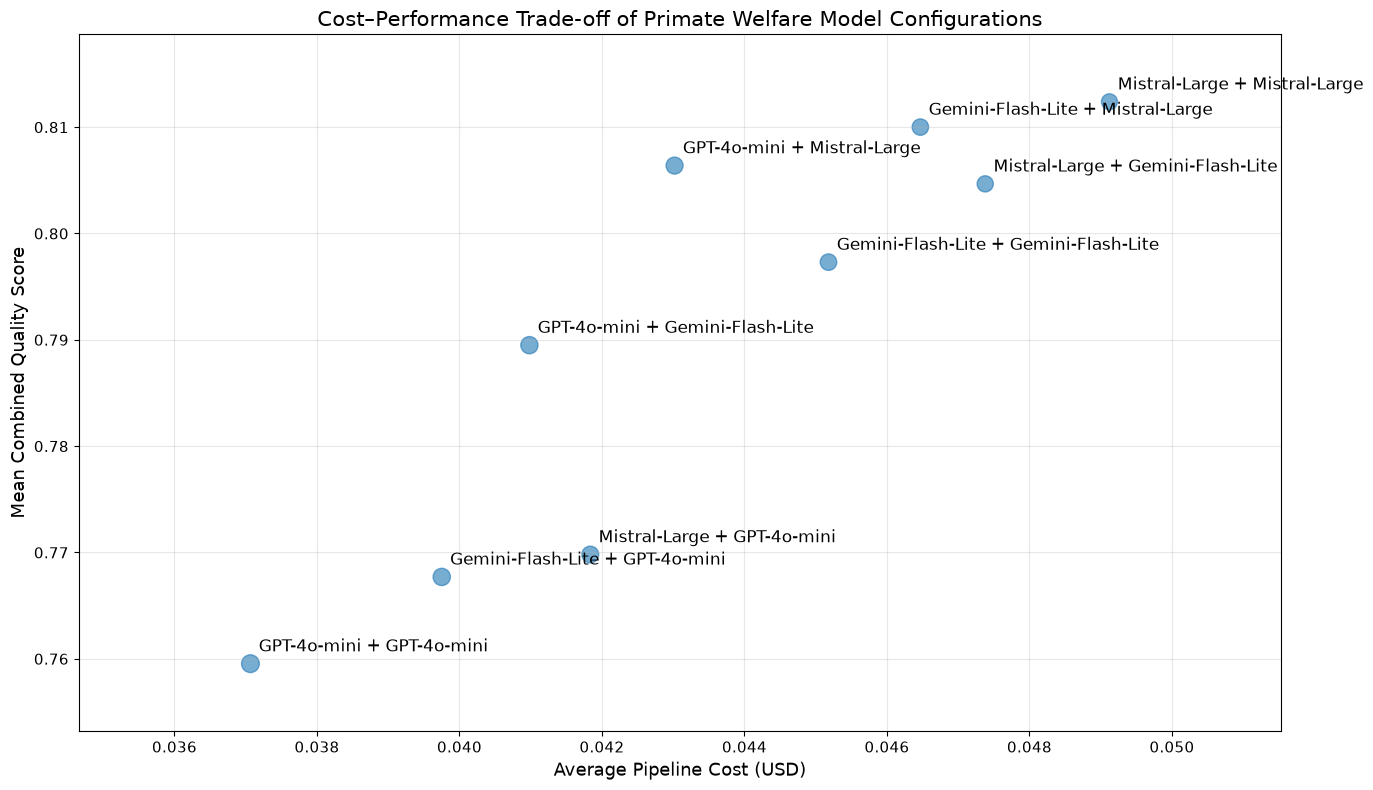

In [ ]:
# visualisation for Primate Welfare

short_names = {
    "gpt-4o-mini": "GPT-4o-mini",
    "mistral-large-2512": "Mistral-Large",
    "gemini-3.1-flash-lite-preview": "Gemini-Flash-Lite"
}

def shorten_pair(pair):
    parts = pair.split(" + ")
    return " + ".join(short_names.get(p, p) for p in parts)

summary_geval["short_pair_name"] = (
    summary_geval["pair_name"].apply(shorten_pair)
)


plt.figure(figsize=(14, 8))

plt.scatter(
    summary_geval["avg_pipeline_cost"],
    summary_geval["avg_quality"],
    s=summary_geval["efficiency"] * 8,
    alpha=0.6
)

for _, row in summary_geval.iterrows():
    plt.annotate(
        row["short_pair_name"],
        (row["avg_pipeline_cost"], row["avg_quality"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=12,          # adjustable
        ha="left",
        va="bottom"
    )

plt.xlabel("Average Pipeline Cost (USD)", fontsize=13)
plt.ylabel("Mean Combined Quality Score", fontsize=13)

plt.title(
    "Cost–Performance Trade-off of Primate Welfare Model Configurations",
    fontsize=15
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.margins(x=0.20, y=0.12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# visualisation for MetaBeeAI

short_names = {
    "gpt-4o": "GPT-4o",
    "gpt-4o-mini": "GPT-4o-mini",
    "gpt-oss-120b": "GPT-OSS-120B",
    "gpt-oss-20b": "GPT-OSS-20B",
    "gpt-5-nano": "GPT-5-Nano",
    "mistral-large-2512": "Mistral-Large",
    "mistral-medium-3.1": "Mistral-Medium",
    "gemini-3.1-flash-lite-preview": "Gemini-Flash-Lite",
    "Llama-4-Maverick-17B-128E-Instruct": "Llama-4-Maverick",
    "Llama-4-Scout-17B-16E-Instruct": "Llama-4-Scout",
    "llama-3.3-70b-instruct": "Llama-3.3-70B",
    "gemma-3-4b-it": "Gemma-3-4B",
    "qwen3.5-27b": "Qwen3.5-27B",
    "qwen3.5-35b-a3b": "Qwen3.5-35B",
    "claude-3-haiku": "Claude-3-Haiku",
    "claude-3.5-haiku": "Claude-3.5-Haiku",
    "o3": "o3"
}

def shorten_pair(pair):
    parts = pair.split(" + ")
    return " + ".join(short_names.get(p, p) for p in parts)


summary_geval["short_pair_name"] = (
    summary_geval["pair_name"].apply(shorten_pair)
)


plt.figure(figsize=(14, 8))

plt.scatter(
    summary_geval["avg_pipeline_cost"],
    summary_geval["avg_quality"],
    s=summary_geval["efficiency"] * 8,
    alpha=0.6
)

for _, row in summary_geval.iterrows():
    plt.annotate(
        row["short_pair_name"],
        (row["avg_pipeline_cost"], row["avg_quality"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=12,          # adjustable
        ha="left",
        va="bottom"
    )

plt.xlabel("Average Pipeline Cost (USD)", fontsize=13)
plt.ylabel("Mean Combined Quality Score", fontsize=13)

plt.title(
    "Cost–Performance Trade-off of Primate Welfare Model Configurations",
    fontsize=15
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.margins(x=0.20, y=0.12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

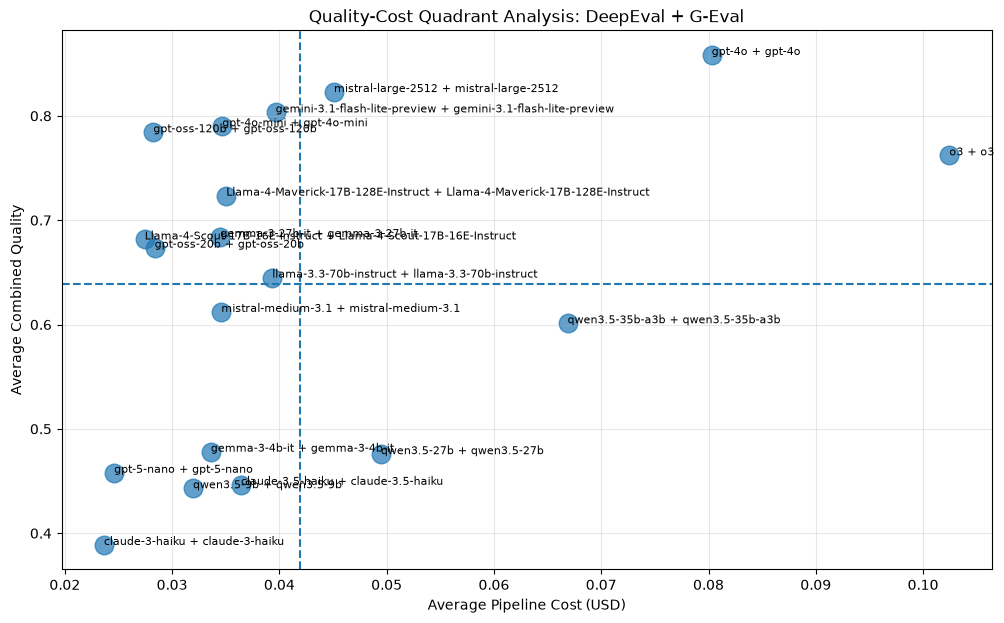

In [ ]:
# quadriant plot 

plt.figure(figsize=(12, 7))

x_mean = summary_geval["avg_pipeline_cost"].mean()
y_mean = summary_geval["avg_quality"].mean()

plt.scatter(
    summary_geval["avg_pipeline_cost"],
    summary_geval["avg_quality"],
    s=180,
    alpha=0.7
)

for _, row in summary_geval.iterrows():
    plt.annotate(
        row["pair_name"],
        (row["avg_pipeline_cost"], row["avg_quality"]),
        fontsize=8
    )

plt.axvline(x=x_mean, linestyle="--")
plt.axhline(y=y_mean, linestyle="--")

plt.xlabel("Average Pipeline Cost (USD)")
plt.ylabel("Average Combined Quality")
plt.title("Quality-Cost Quadrant Analysis: DeepEval + G-Eval")
plt.grid(alpha=0.3)
plt.show()

In [20]:
summary_geval

,index_model_pair,pair_name,answer_model,avg_pipeline_cost,avg_generation_cost,avg_evaluation_cost,avg_faithfulness,avg_precision,avg_recall,avg_completeness,avg_accuracy,avg_quality,n_questions,efficiency
0,0,gpt-4o-mini + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.037066,0.003317,0.033749,0.929263,0.927754,0.860990,0.568337,0.493930,0.759544,189,20.491780
1,1,gpt-4o-mini + mistral-large-2512,openrouter/mistralai/mistral-large-2512,0.043019,0.007606,0.035413,0.934962,0.945398,0.882175,0.652345,0.606462,0.806386,189,18.744972
2,2,gpt-4o-mini + gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview,0.040981,0.005978,0.035004,0.920234,0.949729,0.887341,0.607908,0.581423,0.789497,189,19.264770
3,3,mistral-large-2512 + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.041836,0.007594,0.034242,0.900243,0.943528,0.880997,0.598078,0.532196,0.769806,189,18.400719
4,4,mistral-large-2512 + mistral-large-2512,openrouter/mistralai/mistral-large-2512,0.049123,0.011818,0.037305,0.918640,0.947393,0.898322,0.673573,0.626120,0.812388,189,16.537938
5,5,mistral-large-2512 + gemini-3.1-flash-lite-pre...,openrouter/google/gemini-3.1-flash-lite-preview,0.047379,0.010369,0.037010,0.928339,0.948890,0.910143,0.635465,0.601087,0.804667,189,16.983627
6,6,gemini-3.1-flash-lite-preview + gpt-4o-mini,openrouter/openai/gpt-4o-mini,0.039751,0.004886,0.034865,0.906708,0.944020,0.877641,0.589194,0.523009,0.767702,189,19.312664
7,7,gemini-3.1-flash-lite-preview + mistral-large-...,openrouter/mistralai/mistral-large-2512,0.046469,0.008945,0.037524,0.905868,0.928871,0.899364,0.683645,0.636407,0.810006,189,17.431150
8,8,gemini-3.1-flash-lite-preview + gemini-3.1-fla...,openrouter/google/gemini-3.1-flash-lite-preview,0.045179,0.007663,0.037516,0.900109,0.931252,0.915686,0.639834,0.611329,0.797306,189,17.647645


Statistic

ranking significant in both datasets

In [ ]:
# Create equal-weight Combined Quality Score
merged["combined_quality_equal"] = (
    0.20 * merged["faithfulness_score"] +
    0.20 * merged["contextual_precision_score"] +
    0.20 * merged["contextual_recall_score"] +
    0.20 * merged["completeness_score"] +
    0.20 * merged["accuracy_score"]
)

In [110]:
# stat
sensitivity = (
    merged.groupby("pair_name")
    .agg(
        weighted_quality=("combined_quality", "mean"),
        equal_quality=("combined_quality_equal", "mean")
    )
    .reset_index()
)

sensitivity

,pair_name,weighted_quality,equal_quality
0,Llama-4-Maverick-17B-128E-Instruct + Llama-4-M...,0.723508,0.699092
1,Llama-4-Scout-17B-16E-Instruct + Llama-4-Scout...,0.681517,0.646015
2,claude-3-haiku + claude-3-haiku,0.388719,0.367191
3,claude-3.5-haiku + claude-3.5-haiku,0.446333,0.452556
4,gemini-3.1-flash-lite-preview + gemini-3.1-fla...,0.803288,0.777224
5,gemma-3-27b-it + gemma-3-27b-it,0.683857,0.658129
6,gemma-3-4b-it + gemma-3-4b-it,0.478121,0.476204
7,gpt-4o + gpt-4o,0.858341,0.834355
8,gpt-4o-mini + gpt-4o-mini,0.789969,0.771752
9,gpt-5-nano + gpt-5-nano,0.457892,0.420226


In [111]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    sensitivity["weighted_quality"],
    sensitivity["equal_quality"]
)

print(f"Spearman's rho = {rho:.3f}")
print(f"p-value = {p:.4g}")

Spearman's rho = 0.995
p-value = 2.897e-18


In [112]:
# ranking change
sensitivity["weighted_rank"] = (
    sensitivity["weighted_quality"]
    .rank(ascending=False, method="min")
)

sensitivity["equal_rank"] = (
    sensitivity["equal_quality"]
    .rank(ascending=False, method="min")
)

sensitivity["rank_change"] = (
    sensitivity["equal_rank"] -
    sensitivity["weighted_rank"]
)

sensitivity = sensitivity.sort_values("weighted_rank")

sensitivity

,pair_name,weighted_quality,equal_quality,weighted_rank,equal_rank,rank_change
7,gpt-4o + gpt-4o,0.858341,0.834355,1.0,1.0,0.0
13,mistral-large-2512 + mistral-large-2512,0.822818,0.801529,2.0,2.0,0.0
4,gemini-3.1-flash-lite-preview + gemini-3.1-fla...,0.803288,0.777224,3.0,3.0,0.0
8,gpt-4o-mini + gpt-4o-mini,0.789969,0.771752,4.0,4.0,0.0
10,gpt-oss-120b + gpt-oss-120b,0.784237,0.755595,5.0,5.0,0.0
15,o3 + o3,0.762089,0.739199,6.0,6.0,0.0
0,Llama-4-Maverick-17B-128E-Instruct + Llama-4-M...,0.723508,0.699092,7.0,7.0,0.0
5,gemma-3-27b-it + gemma-3-27b-it,0.683857,0.658129,8.0,8.0,0.0
1,Llama-4-Scout-17B-16E-Instruct + Llama-4-Scout...,0.681517,0.646015,9.0,10.0,1.0
11,gpt-oss-20b + gpt-oss-20b,0.673651,0.654867,10.0,9.0,-1.0


In [113]:
print(
    sensitivity[
        ["pair_name", "weighted_rank", "equal_rank", "rank_change"]
    ].to_string(index=False)
)

print(
    "\nMean absolute rank change:",
    sensitivity["rank_change"].abs().mean()
)

print(
    "Maximum absolute rank change:",
    sensitivity["rank_change"].abs().max()
)

                                                              pair_name  weighted_rank  equal_rank  rank_change
                                                        gpt-4o + gpt-4o            1.0         1.0          0.0
                                mistral-large-2512 + mistral-large-2512            2.0         2.0          0.0
          gemini-3.1-flash-lite-preview + gemini-3.1-flash-lite-preview            3.0         3.0          0.0
                                              gpt-4o-mini + gpt-4o-mini            4.0         4.0          0.0
                                            gpt-oss-120b + gpt-oss-120b            5.0         5.0          0.0
                                                                o3 + o3            6.0         6.0          0.0
Llama-4-Maverick-17B-128E-Instruct + Llama-4-Maverick-17B-128E-Instruct            7.0         7.0          0.0
                                        gemma-3-27b-it + gemma-3-27b-it            8.0         8.0      

Spearman + p value for 5 metrics + cost
- When run this section, run through from the start, individually

In [114]:
cost_quality = (
    merged.groupby("pair_name")
    .agg(
        mean_cost=("pipeline_cost", "mean"),
        mean_quality=("combined_quality", "mean")
    )
    .reset_index()
)

In [ ]:


rho, p = spearmanr(
    cost_quality["mean_cost"],
    cost_quality["mean_quality"]
)

print(f"Spearman's rho = {rho:.3f}")
print(f"p-value = {p:.4g}")

Spearman's rho = 0.430
p-value = 0.06625


In [ ]:

result = linregress(
    cost_quality["mean_cost"],
    cost_quality["mean_quality"]
)

r_squared = result.rvalue ** 2

print(f"R² = {r_squared:.3f}")
print(f"p-value = {result.pvalue:.4g}")

R² = 0.147
p-value = 0.1055


In [78]:
pair_quality = (
    merged.groupby("pair_name")
    .agg(
        mean_quality=("combined_quality", "mean"),
        sd_quality=("combined_quality", "std"),
        n=("combined_quality", "count")
    )
    .reset_index()
    .sort_values("mean_quality", ascending=False)
)

print(pair_quality)

                                           pair_name  mean_quality  \
8            mistral-large-2512 + mistral-large-2512      0.812388   
2  gemini-3.1-flash-lite-preview + mistral-large-...      0.810006   
5                   gpt-4o-mini + mistral-large-2512      0.806386   
6  mistral-large-2512 + gemini-3.1-flash-lite-pre...      0.804667   
0  gemini-3.1-flash-lite-preview + gemini-3.1-fla...      0.797306   
3        gpt-4o-mini + gemini-3.1-flash-lite-preview      0.789497   
7                   mistral-large-2512 + gpt-4o-mini      0.769806   
1        gemini-3.1-flash-lite-preview + gpt-4o-mini      0.767702   
4                          gpt-4o-mini + gpt-4o-mini      0.759544   

   sd_quality    n  
8    0.102107  189  
2    0.097882  189  
5    0.091942  189  
6    0.096727  189  
0    0.095485  189  
3    0.098804  189  
7    0.118406  189  
1    0.118304  189  
4    0.119442  189  


In [82]:
print(pair_quality[["pair_name", "mean_quality", "sd_quality", "n"]])

                                           pair_name  mean_quality  \
4                          gpt-4o-mini + gpt-4o-mini      0.759544   
1        gemini-3.1-flash-lite-preview + gpt-4o-mini      0.767702   
7                   mistral-large-2512 + gpt-4o-mini      0.769806   
3        gpt-4o-mini + gemini-3.1-flash-lite-preview      0.789497   
0  gemini-3.1-flash-lite-preview + gemini-3.1-fla...      0.797306   
6  mistral-large-2512 + gemini-3.1-flash-lite-pre...      0.804667   
5                   gpt-4o-mini + mistral-large-2512      0.806386   
2  gemini-3.1-flash-lite-preview + mistral-large-...      0.810006   
8            mistral-large-2512 + mistral-large-2512      0.812388   

   sd_quality    n  
4    0.119442  189  
1    0.118304  189  
7    0.118406  189  
3    0.098804  189  
0    0.095485  189  
6    0.096727  189  
5    0.091942  189  
2    0.097882  189  
8    0.102107  189  


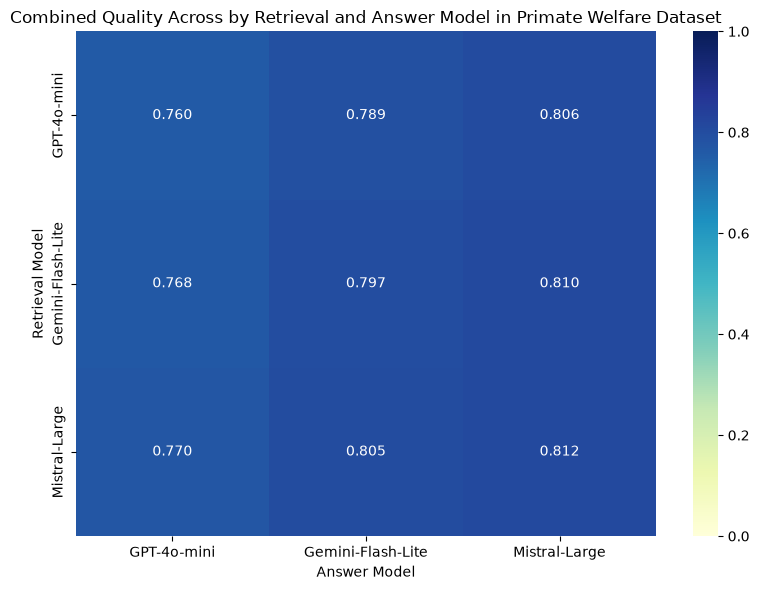

In [ ]:
# Heatmap for primate welfare 
'''

Since Primate Welfare is the only dataset that use 9 pairs, configurations among 3 models, 
both retrieval + answer.  
This is tested to see whether the same LLM achieved the same quality score when acted differently.

'''
# Create shorter model names
short_names = {
    "gpt-4o-mini": "GPT-4o-mini",
    "mistral-large-2512": "Mistral-Large",
    "gemini-3.1-flash-lite-preview": "Gemini-Flash-Lite"
}


# Separate retrieval and answer models
pair_quality[["retrieval_model", "answer_model"]] = (
    pair_quality["pair_name"]
    .str.split(" + ", n=1, expand=True, regex=False)
)

pair_quality["retrieval_model"] = (
    pair_quality["retrieval_model"].replace(short_names)
)

pair_quality["answer_model"] = (
    pair_quality["answer_model"].replace(short_names)
)


heatmap_data = pair_quality.pivot(
    index="retrieval_model",
    columns="answer_model",
    values="mean_quality"
)

order = [
    "GPT-4o-mini",
    "Gemini-Flash-Lite",
    "Mistral-Large"
]

heatmap_data = heatmap_data.reindex(
    index=order,
    columns=order
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.xlabel("Answer Model")
plt.ylabel("Retrieval Model")
plt.title("Combined Quality Across by Retrieval and Answer Model in Primate Welfare Dataset")

plt.tight_layout()
plt.show()